# Bike Sharing Demand Regression

Predict how many bikes get rented in an hour, from weather and calendar data.

Coursework practical (Practical Work 3) from my Artificial Intelligence course at SUPMTI Rabat, taught by Pr. Soufiane Hamida. This is a clean, runnable record of the work, not research.

## Data

Bike Sharing Demand, Capital Bikeshare, Washington DC, 2011 to 2012, from the UCI Machine Learning Repository. Hourly rental counts with weather and seasonal information. Target is `cnt`, the number of bikes rented in that hour.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

## Load the data

The notebook downloads the dataset from UCI itself, so there is no data file to fetch by hand.

In [2]:
import io, urllib.request, zipfile

url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
with urllib.request.urlopen(url, timeout=120) as response:
    data = response.read()
with zipfile.ZipFile(io.BytesIO(data)) as z:
    hour_csv = z.read("hour.csv")
bike_data = pd.read_csv(io.BytesIO(hour_csv))
print(bike_data.shape)
bike_data.head()

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## Check for missing values

In [3]:
print(bike_data.isnull().sum())
print(bike_data["cnt"].describe().round(2))

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
count    17379.00
mean       189.46
std        181.39
min          1.00
25%         40.00
50%        142.00
75%        281.00
max        977.00
Name: cnt, dtype: float64


## Remove outliers

The practical states this rule: drop any hour where the rental count sits more than 3 standard deviations from the mean.

In [4]:
bike_data = bike_data[np.abs(bike_data["cnt"] - bike_data["cnt"].mean()) <= (3 * bike_data["cnt"].std())]
print(bike_data.shape)

(17135, 17)


## Map the coded categories to labels

Exactly as the practical states. One note: the CSV column is called `weathersit`, not `weather`, so the mapping applies to `weathersit`.

The practical maps the categories to labels but does not say how to feed labels to a linear model, so the notebook one-hot encodes them. That step is mine, and it is the only way a linear model can use them.

In [5]:
bike_data["season"] = bike_data.season.map({1: "spring", 2: "summer", 3: "fall", 4: "winter"})
bike_data["weathersit"] = bike_data.weathersit.map({1: "clear", 2: "misty", 3: "light rain/snow", 4: "heavy rain/snow"})
bike_data["holiday"] = bike_data.holiday.map({0: "working_day", 1: "holiday"})
bike_data = pd.get_dummies(bike_data, columns=["season", "weathersit", "holiday"], drop_first=True)
print(bike_data.shape)

(17135, 21)


## Split into train and test

Features are every column except the row id, the date, the two sub-counts (`casual`, `registered`) and the target. Split is 80/20, `random_state=0`, as the practical states.

In [6]:
features = [c for c in bike_data.columns if c not in ("instant", "dteday", "casual", "registered", "cnt")]
print(len(features), "features")
train, test = train_test_split(bike_data, test_size=0.2, random_state=0)
print(train.shape, test.shape)

16 features


(13708, 21) (3427, 21)


## Train three models

Linear regression first, then a decision tree and a random forest, as the practical suggests. Each is scored on mean squared error and R-squared.

In [7]:
models = {
    "Linear regression": LinearRegression(),
    "Decision tree": DecisionTreeRegressor(random_state=0),
    "Random forest": RandomForestRegressor(n_estimators=100, random_state=0),
}
results = {}
for name, model in models.items():
    model.fit(train[features], train["cnt"])
    predictions = model.predict(test[features])
    results[name] = (mean_squared_error(test["cnt"], predictions), r2_score(test["cnt"], predictions))
    print(f"{name}: MSE {results[name][0]:.2f}, R-squared {results[name][1]:.4f}")

Linear regression: MSE 16883.84, R-squared 0.4033


Decision tree: MSE 2970.11, R-squared 0.8950


Random forest: MSE 1722.51, R-squared 0.9391


## Read the results

Linear regression underfits here. It explains about 40 percent of the variance. The tree models do far better, and the random forest is the best of the three. That gap is the honest finding: hourly rental counts do not follow a straight line from weather alone.

In [8]:
linear = models["Linear regression"]
top = sorted(zip(features, linear.coef_), key=lambda t: -abs(t[1]))[:5]
print("Strongest linear coefficients:")
for feature, coef in top:
    print(f"  {feature}: {coef:.2f}")

Strongest linear coefficients:
  temp: 216.67
  hum: -177.31
  atemp: 127.02
  season_winter: 69.22
  yr: 65.44


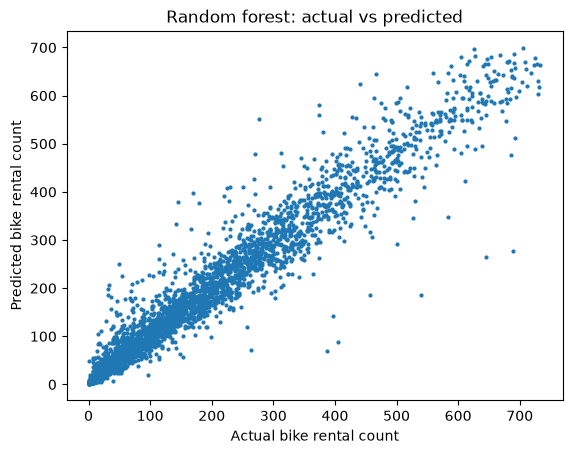

In [9]:
plt.scatter(test["cnt"], models["Random forest"].predict(test[features]), s=4)
plt.xlabel("Actual bike rental count")
plt.ylabel("Predicted bike rental count")
plt.title("Random forest: actual vs predicted")
plt.show()

## Limits

This is a coursework baseline, not a finished product. It treats each hour as independent and ignores time order, so it misses daily and weekly patterns a real model would use. The numbers above are what the code actually produced on the full hourly data.